# Chapter 14: Heuristics, Anchors, and Biased Beliefs

This notebook reruns four worked examples from the chapter: a hiring label read as a posterior (representativeness), an asking price that anchors a valuation, balanced evidence that polarizes two people (confirmation bias), and a linear forecast of a compounding balance. Every example is hypothetical, as in the book; a few extra input values are added for comparison. Where the book rounds before multiplying, the exact values are shown.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def vline(ax, x, text=None, col="grey", style="dashed", y_frac=0.95, ha="left", lw=1.4):
    """Vertical reference line with an optional label near the top of the axes."""
    ax.axvline(x, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x, y_frac), xycoords=("data", "axes fraction"), xytext=(5 if ha == "left" else -5, 0),
                    textcoords="offset points", ha=ha, va="top", color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def future_value(pv, r, T):
    """pv (1 + r)^T."""
    return pv * (1.0 + r) ** T


def compound_value(P, r, T):
    """Alias of future_value for compounding a principal P at rate r for T periods."""
    return future_value(P, r, T)


def anchor_judgment(m, a, lam):
    """Anchored judgment J = (1 - lambda) m(I) + lambda a (anchoring-and-insufficient-adjustment).

    Book (ch014): m = 24,000, lambda = 0.25 gives J_H = 26,000 at a = 32,000 and J_L = 23,000 at a = 20,000.
    """
    return (1 - lam) * m + lam * a


def linear_growth_forecast(P, r, T):
    """Linear (simple-interest) forecast P + T (r P) (exponential-growth-bias).

    Book (ch014): 10,000 + 30 (700) = 31,000 at r = 0.07, T = 30; compounding gives 76,123.
    """
    return P + T * r * P


def bayes_posterior(prior, p_e_h, p_e_not):
    """Posterior P(H | E) by Bayes' rule (representativeness-heuristic).

    Book (ch014): 0.80(0.10) / (0.80(0.10) + 0.30(0.90)) = 0.228571, printed as 0.229.
    """
    num_ = p_e_h * prior
    return num_ / (num_ + p_e_not * (1 - prior))


def weighted_odds_posterior(prior, lrs, weights):
    """Posterior after multiplying prior odds by LR_i ** w_i (confirmation-bias).

    Book (ch014): prior 0.75, LR 3 (weight 1) and 1/3 (weight 0.5): odds 5.196, posterior 0.8386.
    Returns {"odds": final odds, "posterior": posterior probability}.
    """
    odds = prior / (1 - prior)
    for lr, w in zip(lrs, weights):
        odds *= lr ** w
    return {"odds": odds, "posterior": odds / (1 + odds)}


plt.rcParams.update(HOUSE_RC)


choice = SimpleNamespace(future_value=future_value, compound_value=compound_value)


behavioral = SimpleNamespace(anchor_judgment=anchor_judgment, linear_growth_forecast=linear_growth_forecast, weighted_odds_posterior=weighted_odds_posterior)


information = SimpleNamespace(bayes_posterior=bayes_posterior)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'representativeness-heuristic': {'base': 0.1,
                                  'p_label_high': 0.8,
                                  'p_label_other': 0.3,
                                  'value': 150000,
                                  'cost': 50000,
                                  'posterior_printed_as': 0.229,
                                  'posterior_exact_6dp': 0.228571,
                                  'net_printed_as': -15650,
                                  'net_exact_2dp': -15714.29,
                                  'perceived_net': 70000},
 'anchoring-and-insufficient-adjustment': {'m': 24000,
                                           'lam': 0.25,
                                           'a_H': 32000,
                                           'a_L': 20000,
                                           'J_H': 26000,
                                           'J_L': 23000,
                                           'gap': 3000,
                                           'bid_share': 0.95,
                                           'bid_H': 24700,
                                           'bid_L': 21850,
                                           'bid_lam0': 22800},
 'confirmation-bias': {'p_A': 0.75,
                       'p_B': 0.25,
                       'lr_F': 3,
                       'w_confirm': 1,
                       'w_contra': 0.5,
                       'odds_A': 5.196,
                       'post_A': 0.839,
                       'odds_B': 0.192,
                       'post_B': 0.161,
                       'gap_printed_as': 0.678,
                       'gap_exact_4dp': 0.6772},
 'exponential-growth-bias': {'P': 10000,
                             'r': 0.07,
                             'T': 30,
                             'linear': 31000,
                             'compound': 76123,
                             'threshold': 60000,
                             'one_year': 10700},
 'constructed': {'representativeness-heuristic': {'base': [0.05, 0.2, 0.3], 'fp': [0.1, 0.5]},
                 'anchoring-and-insufficient-adjustment': {'lam': [0.1, 0.5], 'aH': [28000, 40000]},
                 'confirmation-bias': {'wc': [0], 'lr': [2, 5]},
                 'exponential-growth-bias': {'r': [0.03, 0.05, 0.09], 'T': [10, 20]}}}


def hiring_picture(base=0.10, fp=0.30):
    bv = BV["representativeness-heuristic"]
    p_h, value, cost = bv["p_label_high"], bv["value"], bv["cost"]
    top = p_h * base
    other = fp * (1 - base)
    den = top + other
    post = information.bayes_posterior(base, p_h, fp)
    ev = post * value
    net = ev - cost
    perceived = p_h * value - cost
    breakeven = cost / value
    hire = net > 0
    fig, ax = new_figure()
    bar_compare(ax, ["Bayesian posterior", "Likelihood used as posterior"], [post, p_h],
                colors=["teal", "terracotta"], value_labels=[num(post, 4), num(p_h, 2)],
                ylabel="Probability the hire is a high performer", xlabel="Probability used in the decision")
    if breakeven - 0.07 < post < breakeven + 0.01:
        # The value label would sit on the break-even line: move it inside the bar.
        tag = ax.texts[0]
        tag.set_position((0, -4))
        tag.set_va("top")
        tag.set_color("white")
    hline(ax, breakeven, col="ink")
    label(ax, 1.38, breakeven, f"break-even {num(breakeven, 4)}", col="ink", dx=0, dy=4)
    ax.set_xlim(-0.5, 2.1)
    ax.set_ylim(0, 1.0)
    metrics = {"Posterior P(H | label)": num(post, 4), "Bayesian expected net value": money(net),
               "Perceived net value": money(perceived), "Bayesian decision": "Hire" if hire else "Do not hire",
               "Resemblance decision": "Hire"}
    calc = (f"P(H | E) = 0.80 x {num(base, 2)} / (0.80 x {num(base, 2)} + {num(fp, 2)} x {num(1 - base, 2)}) = "
            f"{num(top, 4)} / {num(den, 4)} = {num(post, 4)}")
    note = ""
    if base == bv["base"] and fp == bv["p_label_other"]:
        note = (" The book rounds the posterior to 0.229 before multiplying and prints -$15,650; the exact posterior "
                "0.228571 gives -$15,714.29. The decision is the same.")
    interp = (f"{calc}. Expected net value is 150,000 x {num(top, 4)} / {num(den, 4)} - 50,000 = {money(ev)} - "
              f"$50,000 = {money(net)}, so the Bayesian firm {'hires' if hire else 'does not hire'}. Treating the "
              f"0.80 likelihood as the posterior gives 0.80 x 150,000 - 50,000 = $70,000, so the evaluator hires"
              f"{' as well' if hire else ''}.{note}")
    steps = [f"0.80 x {num(base, 2)} = {num(top, 4)}",
             f"{num(fp, 2)} x {num(1 - base, 2)} = {num(other, 4)}",
             f"P(H | E) = {num(top, 4)} / ({num(top, 4)} + {num(other, 4)}) = {num(top, 4)} / {num(den, 4)} = {num(post, 4)}",
             f"Bayesian net = 150,000 x {num(top, 4)} / {num(den, 4)} - 50,000 = {num(ev)} - 50,000 = {num(net)}",
             "Perceived net = 0.80 x 150,000 - 50,000 = 120,000 - 50,000 = 70,000",
             f"Break-even probability = 50,000 / 150,000 = {num(breakeven, 4)}"]
    alt = (f"Two bars: the Bayesian posterior {num(post, 4)} and the likelihood 0.80 used as if it were the posterior, "
           f"against a break-even line at {num(breakeven, 4)}. The posterior is "
           f"{'above' if hire else 'below'} the line.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def anchor_picture(lam=0.25, a_high=32_000):
    bv = BV["anchoring-and-insufficient-adjustment"]
    m, aL, share = bv["m"], bv["a_L"], bv["bid_share"]
    jh = behavioral.anchor_judgment(m, a_high, lam)
    jl = behavioral.anchor_judgment(m, aL, lam)
    gap = jh - jl
    bh, bl = share * jh, share * jl
    fig, ax = new_figure()
    ax.plot([12_000, 48_000], [0, 0], color=PALETTE["grey"], linewidth=1)
    vline(ax, m, f"evidence m(I) = {money(m, 0)}", col="ink", y_frac=0.97)
    mark(ax, a_high, 1.0, f"high anchor {money(a_high, 0)}", col="terracotta", dx=0, dy=10, ha="center")
    mark(ax, aL, 1.0, f"low anchor {money(aL, 0)}", col="navy", dx=0, dy=-10, ha="center", va="top")
    ax.annotate("", xy=(jh, 0.42), xytext=(a_high, 0.95), arrowprops={"arrowstyle": "->", "color": PALETTE["terracotta"]})
    ax.annotate("", xy=(jl, 0.42), xytext=(aL, 0.95), arrowprops={"arrowstyle": "->", "color": PALETTE["navy"]})
    mark(ax, jh, 0.35, f"J_H = {money(jh, 0)}", col="terracotta", dx=8, dy=-14, va="top")
    mark(ax, jl, 0.35, f"J_L = {money(jl, 0)}", col="navy", dx=-8, dy=-14, ha="right", va="top")
    label(ax, 30_000, -0.35, f"judgment gap {money(gap, 0)}, bid gap {money(bh - bl, 0)}", col="ink", ha="center")
    ax.set_xlim(12_000, 48_000)
    ax.set_ylim(-0.6, 1.6)
    ax.set_yticks([0.35, 1.0], ["judgment", "anchor"])
    ax.set_xlabel("Van value ($)")
    ax.set_ylabel("Position")
    metrics = {"Judgment after high anchor J_H": money(jh, 0), "Judgment after low anchor J_L": money(jl, 0),
               "Judgment gap": money(gap, 0), "Bid after high anchor": money(bh, 0),
               "Bid after low anchor": money(bl, 0), "Bid gap": money(bh - bl, 0)}
    keep = 1 - lam
    if lam == 0:
        verdict = "With no residual anchor weight both judgments equal the evidence, so the anchors leave no gap."
    else:
        verdict = (f"The {money(a_high - aL, 0)} anchor difference becomes a {money(gap, 0)} valuation difference, "
                   f"{num(lam, 2)} of it.")
    interp = (f"J_H = {num(keep, 2)} x 24,000 + {num(lam, 2)} x {num(a_high, 0)} = {num(keep * m, 0)} + "
              f"{num(lam * a_high, 0)} = {money(jh, 0)} and J_L = {num(keep, 2)} x 24,000 + {num(lam, 2)} x 20,000 = "
              f"{num(keep * m, 0)} + {num(lam * aL, 0)} = {money(jl, 0)}. {verdict} Bidding 95 percent of each "
              f"judgment gives {money(bh, 0)} and {money(bl, 0)}.")
    steps = [f"J_H = {num(keep, 2)} x 24,000 + {num(lam, 2)} x {num(a_high, 0)} = {num(keep * m, 0)} + {num(lam * a_high, 0)} = {num(jh, 0)}",
             f"J_L = {num(keep, 2)} x 24,000 + {num(lam, 2)} x 20,000 = {num(keep * m, 0)} + {num(lam * aL, 0)} = {num(jl, 0)}",
             f"Gap = {num(lam, 2)} x ({num(a_high, 0)} - 20,000) = {num(gap, 0)}",
             f"Bids = 0.95 x {num(jh, 0)} = {num(bh, 0)} and 0.95 x {num(jl, 0)} = {num(bl, 0)}"]
    alt = (f"A value line from $12,000 to $48,000. Anchors at {money(aL, 0)} and {money(a_high, 0)} pull judgments toward "
           f"them from the evidence value $24,000: J_L = {money(jl, 0)} and J_H = {money(jh, 0)}, a gap of "
           f"{money(gap, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def polarization_picture(wc=0.5, lr=3):
    bv = BV["confirmation-bias"]
    pa, pb = bv["p_A"], bv["p_B"]
    a = behavioral.weighted_odds_posterior(pa, [lr, 1 / lr], [1, wc])
    b = behavioral.weighted_odds_posterior(pb, [1 / lr, lr], [1, wc])
    gap = a["posterior"] - b["posterior"]
    fig, ax = new_figure()
    ax.plot([0, 1], [0, 0], color=PALETTE["grey"], linewidth=1)
    ax.plot([0, 1], [1, 1], color=PALETTE["grey"], linewidth=1)
    mark(ax, pa, 1, f"Ava prior {num(pa, 2)}", col="teal", dx=0, dy=10, ha="center")
    mark(ax, pb, 1, f"Ben prior {num(pb, 2)}", col="navy", dx=0, dy=10, ha="center")
    ax.annotate("", xy=(a["posterior"], 0.06), xytext=(pa, 0.94), arrowprops={"arrowstyle": "->", "color": PALETTE["teal"]})
    ax.annotate("", xy=(b["posterior"], 0.06), xytext=(pb, 0.94), arrowprops={"arrowstyle": "->", "color": PALETTE["navy"]})
    mark(ax, a["posterior"], 0, f"Ava {num(a['posterior'], 4)}", col="teal", dx=-6, dy=-12, ha="right", va="top")
    mark(ax, b["posterior"], 0, f"Ben {num(b['posterior'], 4)}", col="navy", dx=6, dy=-12, ha="left", va="top")
    label(ax, 0.5, 0.5, f"gap {num(pa - pb, 2)} before, {num(gap, 4)} after", col="ink", ha="center", va="center")
    ax.set_xlim(0, 1)
    ax.set_ylim(-0.5, 1.45)
    ax.set_yticks([0, 1], ["after both signals", "prior"])
    ax.set_xlabel("Probability the startup is high quality")
    ax.set_ylabel("Belief")
    metrics = {"Ava's final odds": num(a["odds"], 4), "Ava's posterior": num(a["posterior"], 4),
               "Ben's final odds": num(b["odds"], 4), "Ben's posterior": num(b["posterior"], 4),
               "Gap before": num(pa - pb, 2), "Gap after": num(gap, 4)}
    lr_t = num(lr, 0)
    if wc == 1:
        verdict = ("With full weight on both signals they cancel, posteriors stay at the priors and the gap stays at "
                   "0.50.")
    else:
        verdict = (f"Identical evidence widens the disagreement from 0.50 to {num(gap, 4)}.")
    note = ""
    if wc == 0.5 and lr == 3:
        note = " The book says about 0.678 because it subtracts the rounded posteriors 0.839 and 0.161; the exact gap is 0.6772."
    interp = (f"Ava's odds are 3 x {lr_t} x (1/{lr_t})^{wc:g} = {num(a['odds'], 4)}, so her posterior is "
              f"{num(a['odds'], 4)} / {num(1 + a['odds'], 4)} = {num(a['posterior'], 4)}. Ben's odds are (1/3) x "
              f"(1/{lr_t}) x {lr_t}^{wc:g} = {num(b['odds'], 4)}, so his posterior is {num(b['posterior'], 4)}. "
              f"{verdict}{note}")
    steps = [f"Ava: odds = 3 x {lr_t} x (1/{lr_t})^{wc:g} = {num(a['odds'], 4)}",
             f"Ava: posterior = {num(a['odds'], 4)} / (1 + {num(a['odds'], 4)}) = {num(a['posterior'], 4)}",
             f"Ben: odds = (1/3) x (1/{lr_t}) x {lr_t}^{wc:g} = {num(b['odds'], 4)}",
             f"Ben: posterior = {num(b['odds'], 4)} / (1 + {num(b['odds'], 4)}) = {num(b['posterior'], 4)}",
             f"Gap = {num(a['posterior'], 4)} - {num(b['posterior'], 4)} = {num(gap, 4)}"]
    alt = (f"Ava moves from prior 0.75 to {num(a['posterior'], 4)} and Ben from 0.25 to {num(b['posterior'], 4)} after "
           f"one favorable and one unfavorable signal of likelihood ratio {lr_t}; the gap is {num(gap, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def growth_picture(r=0.07, years=30):
    T = years
    bv = BV["exponential-growth-bias"]
    P, need = bv["P"], bv["threshold"]
    lin = behavioral.linear_growth_forecast(P, r, T)
    comp = choice.compound_value(P, r, T)
    grid = np.arange(0, T + 1)
    fig, ax = new_figure()
    ax.plot(grid, [P * (1 + r) ** t for t in grid], color=PALETTE["teal"], linewidth=2.2)
    ax.plot(grid, [P * (1 + r * t) for t in grid], color=PALETTE["gold"], linewidth=2.2, linestyle="dashed")
    hline(ax, need, "needs $60,000", col="terracotta")
    if 0 < need - comp < 0.15 * need:
        # Just under the requirement: label below the point so it does not sit on the $60,000 line.
        mark(ax, T, comp, f"compound {money(comp, 0)}", col="teal", dx=-10, dy=0, ha="right", va="center")
    else:
        mark(ax, T, comp, f"compound {money(comp, 0)}", col="teal", dx=-8, dy=6, ha="right")
    mark(ax, T, lin, f"linear {money(lin, 0)}", col="gold", dx=-8, dy=-10, ha="right", va="top")
    ax.set_xlim(0, T + 1)
    ax.locator_params(axis="x", integer=True)
    ax.set_ylim(0, max(comp, need) * 1.15)
    ax.set_xlabel("Years")
    ax.set_ylabel("Balance ($)")
    accept_c, accept_l = comp >= need, lin >= need
    metrics = {"Linear forecast": money(lin, 0), "Compound balance": money(comp, 0),
               "Understatement": money(comp - lin, 0),
               "Decision on the linear forecast": "Accept" if accept_l else "Reject",
               "Decision on the compound balance": "Accept" if accept_c else "Reject"}
    first = P * r
    if accept_c and not accept_l:
        verdict = "Only the compound balance clears $60,000, so the linear forecast wrongly rejects the contribution."
    elif accept_c:
        verdict = "Both forecasts clear $60,000, so the bias does not change the decision here."
    else:
        verdict = "Neither balance reaches $60,000, so both lead to rejection; the bias does not change the decision here."
    interp = (f"Linear reasoning adds the first year's {money(first, 0)} {T} times: 10,000 + {T} x {num(first, 0)} = "
              f"{num(lin, 0)}. Compounding gives 10,000 x {num((1 + r) ** T, 4)} = {num(comp, 0)} "
              f"({num(1 + r, 2)}^{T} = {num((1 + r) ** T, 4)}), "
              f"{money(comp - lin, 0)} more. {verdict}")
    steps = [f"First-year interest = {num(r, 2)} x 10,000 = {num(first, 0)}",
             f"Linear = 10,000 + {T} x {num(first, 0)} = {num(lin, 0)}",
             f"{num(1 + r, 2)}^{T} = {num((1 + r) ** T, 4)}",
             f"Compound = 10,000 x {num((1 + r) ** T, 4)} = {num(comp, 0)}",
             f"Understatement = {num(comp, 2)} - {num(lin, 0)} = {num(comp - lin, 2)}"]
    alt = (f"Balance paths over {T} years at {num(100 * r, 0)} percent: the compound curve ends at {money(comp, 0)} and the "
           f"straight linear forecast at {money(lin, 0)}, against a $60,000 requirement.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Representativeness heuristic: resemblance is not the posterior

Ten percent of applicants become high performers. The label appears for 80 percent of them and for 30 percent of everyone else. A high performer is worth \$150,000 and hiring costs \$50,000.

$$P(H\mid E)=\frac{P(E\mid H)P(H)}{P(E\mid H)P(H)+P(E\mid\neg H)P(\neg H)}$$

Treating the likelihood as the posterior gives $0.80(\$150{,}000)-\$50{,}000=\$70{,}000$.

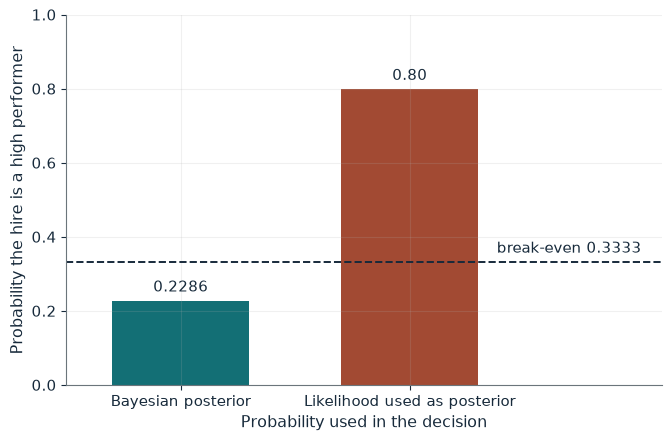

Posterior P(H | label)       0.2286
Bayesian expected net value  -$15,714.29
Perceived net value          $70,000.00
Bayesian decision            Do not hire
Resemblance decision         Hire

Worked steps:
  1. 0.80 x 0.10 = 0.0800
  2. 0.30 x 0.90 = 0.2700
  3. P(H | E) = 0.0800 / (0.0800 + 0.2700) = 0.0800 / 0.3500 = 0.2286
  4. Bayesian net = 150,000 x 0.0800 / 0.3500 - 50,000 = 34,285.71 - 50,000 = -15,714.29
  5. Perceived net = 0.80 x 150,000 - 50,000 = 120,000 - 50,000 = 70,000
  6. Break-even probability = 50,000 / 150,000 = 0.3333

P(H | E) = 0.80 x 0.10 / (0.80 x 0.10 + 0.30 x 0.90) = 0.0800 / 0.3500 = 0.2286. Expected net value is 150,000 x 0.0800 / 0.3500 - 50,000 = $34,285.71 - $50,000 = -$15,714.29, so the Bayesian firm does not hire. Treating the 0.80 likelihood as the posterior gives 0.80 x 150,000 - 50,000 = $70,000, so the evaluator hires. The book rounds the posterior to 0.229 before multiplying and prints -$15,650; the exact posterior 0.228571 gives -$15,714.29. Th

In [2]:
show(hiring_picture(base=0.10, fp=0.30))

Change one input, `base`, and hold the others at the book's values:

In [3]:
sweep(hiring_picture, 'base', [0.05, 0.1, 0.2, 0.3], {'fp': 0.3}, ['Posterior P(H | label)', 'Bayesian expected net value', 'Bayesian decision'])

base | Posterior P(H | label) | Bayesian expected net value | Bayesian decision
0.05 | 0.1231 | -$31,538.46 | Do not hire
0.1 | 0.2286 | -$15,714.29 | Do not hire
0.2 | 0.4000 | $10,000.00 | Hire
0.3 | 0.5333 | $30,000.00 | Hire


The exact posterior is 0.08 / 0.35 = 0.2286, so the expected net value is 34,285.71 - 50,000 = -\$15,714.29 and the Bayesian firm does not hire. The book rounds the posterior to 0.229 first and prints -\$15,650; the decision is the same. Reading 0.80 as the posterior reverses it.

## 2. Anchoring and insufficient adjustment: how far an anchor pulls a valuation

The evidence supports \$24,000. With residual anchor weight $\lambda$ the judgment is

$$J=(1-\lambda)m(I)+\lambda a$$

and the bid is 95 percent of the judgment.

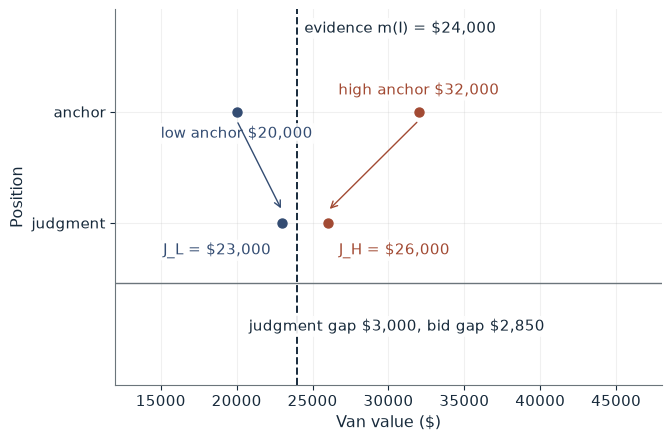

Judgment after high anchor J_H  $26,000
Judgment after low anchor J_L   $23,000
Judgment gap                    $3,000
Bid after high anchor           $24,700
Bid after low anchor            $21,850
Bid gap                         $2,850

Worked steps:
  1. J_H = 0.75 x 24,000 + 0.25 x 32,000 = 18,000 + 8,000 = 26,000
  2. J_L = 0.75 x 24,000 + 0.25 x 20,000 = 18,000 + 5,000 = 23,000
  3. Gap = 0.25 x (32,000 - 20,000) = 3,000
  4. Bids = 0.95 x 26,000 = 24,700 and 0.95 x 23,000 = 21,850

J_H = 0.75 x 24,000 + 0.25 x 32,000 = 18,000 + 8,000 = $26,000 and J_L = 0.75 x 24,000 + 0.25 x 20,000 = 18,000 + 5,000 = $23,000. The $12,000 anchor difference becomes a $3,000 valuation difference, 0.25 of it. Bidding 95 percent of each judgment gives $24,700 and $21,850.


In [4]:
show(anchor_picture(lam=0.25, a_high=32_000))

Change one input, `lam`, and hold the others at the book's values:

In [5]:
sweep(anchor_picture, 'lam', [0, 0.1, 0.25, 0.5], {'a_high': 32000}, ['Judgment after high anchor J_H', 'Judgment after low anchor J_L', 'Judgment gap', 'Bid gap'])

lam | Judgment after high anchor J_H | Judgment after low anchor J_L | Judgment gap | Bid gap
0 | $24,000 | $24,000 | $0 | $0
0.1 | $24,800 | $23,600 | $1,200 | $1,140
0.25 | $26,000 | $23,000 | $3,000 | $2,850
0.5 | $28,000 | $22,000 | $6,000 | $5,700


At $\lambda=0.25$ the \$12,000 anchor difference becomes a \$3,000 valuation gap (26,000 against 23,000) and bids of \$24,700 and \$21,850. An independent appraisal that sets $\lambda=0$ gives \$24,000 and a bid of \$22,800 after either anchor.

## 3. Confirmation bias: same evidence, wider disagreement

Ava starts at 0.75 and Ben at 0.25. Each sees one favorable signal with $LR=3$ and one unfavorable with $LR=1/3$, giving weight 1 to confirming and $w$ to contradicting evidence:

$$\log O_{t+1}=\log O_t+w(s_t,p_t)\log LR(s_t)$$

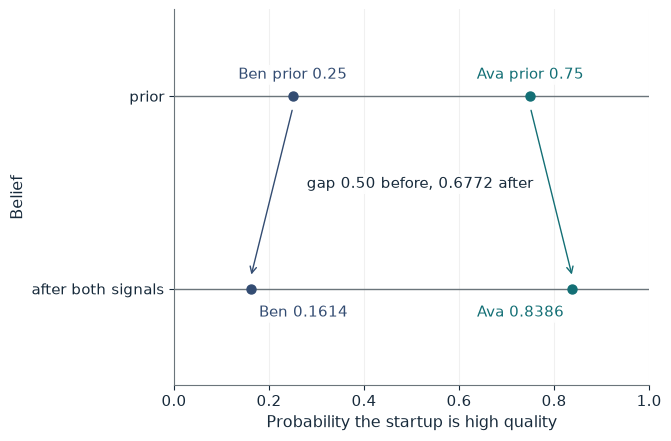

Ava's final odds  5.1962
Ava's posterior   0.8386
Ben's final odds  0.1925
Ben's posterior   0.1614
Gap before        0.50
Gap after         0.6772

Worked steps:
  1. Ava: odds = 3 x 3 x (1/3)^0.5 = 5.1962
  2. Ava: posterior = 5.1962 / (1 + 5.1962) = 0.8386
  3. Ben: odds = (1/3) x (1/3) x 3^0.5 = 0.1925
  4. Ben: posterior = 0.1925 / (1 + 0.1925) = 0.1614
  5. Gap = 0.8386 - 0.1614 = 0.6772

Ava's odds are 3 x 3 x (1/3)^0.5 = 5.1962, so her posterior is 5.1962 / 6.1962 = 0.8386. Ben's odds are (1/3) x (1/3) x 3^0.5 = 0.1925, so his posterior is 0.1614. Identical evidence widens the disagreement from 0.50 to 0.6772. The book says about 0.678 because it subtracts the rounded posteriors 0.839 and 0.161; the exact gap is 0.6772.


In [6]:
show(polarization_picture(wc=0.5, lr=3))

Change one input, `wc`, and hold the others at the book's values:

In [7]:
sweep(polarization_picture, 'wc', [0, 0.5, 1], {'lr': 3}, ["Ava's posterior", "Ben's posterior", 'Gap after'])

wc | Ava's posterior | Ben's posterior | Gap after
0 | 0.9000 | 0.1000 | 0.8000
0.5 | 0.8386 | 0.1614 | 0.6772
1 | 0.7500 | 0.2500 | 0.5000


With half weight on contradiction Ava's odds are 5.1962 and her posterior 0.8386; Ben's is 0.1614. The gap widens from 0.50 to 0.6772 (the book says about 0.678, the difference of its rounded posteriors). With equal weights the signals cancel and the gap stays 0.50.

## 4. Exponential-growth bias: linear versus compound growth

A one-time \$10,000 contribution earns 7 percent for 30 years.

$$B_T=P(1+r)^T, \qquad \widetilde B_T=P(1+rT)$$

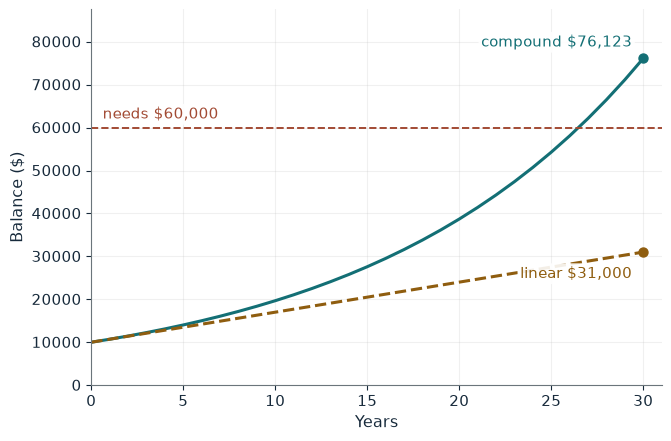

Linear forecast                   $31,000
Compound balance                  $76,123
Understatement                    $45,123
Decision on the linear forecast   Reject
Decision on the compound balance  Accept

Worked steps:
  1. First-year interest = 0.07 x 10,000 = 700
  2. Linear = 10,000 + 30 x 700 = 31,000
  3. 1.07^30 = 7.6123
  4. Compound = 10,000 x 7.6123 = 76,123
  5. Understatement = 76,122.55 - 31,000 = 45,122.55

Linear reasoning adds the first year's $700 30 times: 10,000 + 30 x 700 = 31,000. Compounding gives 10,000 x 7.6123 = 76,123 (1.07^30 = 7.6123), $45,123 more. Only the compound balance clears $60,000, so the linear forecast wrongly rejects the contribution.


In [8]:
show(growth_picture(r=0.07, years=30))

Change one input, `r`, and hold the others at the book's values:

In [9]:
sweep(growth_picture, 'r', [0.03, 0.05, 0.07, 0.09], {'years': 30}, ['Linear forecast', 'Compound balance', 'Decision on the linear forecast', 'Decision on the compound balance'])

r | Linear forecast | Compound balance | Decision on the linear forecast | Decision on the compound balance
0.03 | $19,000 | $24,273 | Reject | Reject
0.05 | $25,000 | $43,219 | Reject | Reject
0.07 | $31,000 | $76,123 | Reject | Accept
0.09 | $37,000 | $132,677 | Reject | Accept


Linear reasoning gives \$31,000 and compounding \$76,123. Against a \$60,000 requirement, only the compound balance justifies the contribution, so the linear shortcut reverses the decision.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

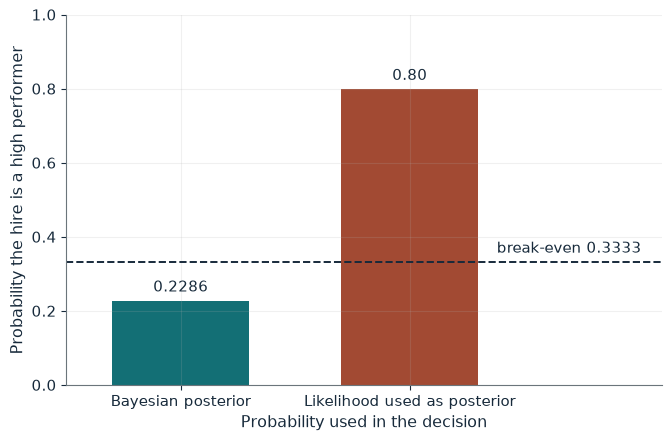

Posterior P(H | label)       0.2286
Bayesian expected net value  -$15,714.29
Perceived net value          $70,000.00
Bayesian decision            Do not hire
Resemblance decision         Hire

Worked steps:
  1. 0.80 x 0.10 = 0.0800
  2. 0.30 x 0.90 = 0.2700
  3. P(H | E) = 0.0800 / (0.0800 + 0.2700) = 0.0800 / 0.3500 = 0.2286
  4. Bayesian net = 150,000 x 0.0800 / 0.3500 - 50,000 = 34,285.71 - 50,000 = -15,714.29
  5. Perceived net = 0.80 x 150,000 - 50,000 = 120,000 - 50,000 = 70,000
  6. Break-even probability = 50,000 / 150,000 = 0.3333

P(H | E) = 0.80 x 0.10 / (0.80 x 0.10 + 0.30 x 0.90) = 0.0800 / 0.3500 = 0.2286. Expected net value is 150,000 x 0.0800 / 0.3500 - 50,000 = $34,285.71 - $50,000 = -$15,714.29, so the Bayesian firm does not hire. Treating the 0.80 likelihood as the posterior gives 0.80 x 150,000 - 50,000 = $70,000, so the evaluator hires. The book rounds the posterior to 0.229 before multiplying and prints -$15,650; the exact posterior 0.228571 gives -$15,714.29. Th

In [10]:
show(hiring_picture(base=0.10, fp=0.30))

## Practice

**1.** With base rate 0.10 and a label rate of 0.10 among others, is hiring worth it?

<details><summary>Answer</summary>

P = 0.08 / (0.08 + 0.09) = 0.4706; net = 150,000 x 0.08 / 0.17 - 50,000 = 70,588.24 - 50,000 = \$20,588.24, so hire.

</details>

**2.** With lambda = 0.25 and a high asking price of \$40,000, what is the bid gap?

<details><summary>Answer</summary>

J_H = 18,000 + 10,000 = 28,000 and J_L = 23,000; bids are 26,600 and 21,850, a gap of \$4,750.

</details>

**3.** At 9 percent for 20 years, what do the linear and compound formulas give?

<details><summary>Answer</summary>

Linear: 10,000 + 20 x 900 = \$28,000. Compound: 10,000 x 1.09^20 = \$56,044.

</details>